# Robust CIFAR-10 classification with 500 images
Seeds: **split seed = 42**, **corruption seed = 1234**, **training seeds = 0, 1, 2**. Train from scratch, Inception-style CNN, <= 1M params, on-the-fly augmentation, <= 60 epochs.
All hyperparameters are chosen on the 100-image validation split only. Test sets are used once at the end.

In [2]:
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F, random, copy, time
import matplotlib.pyplot as plt, pandas as pd
import torchvision, torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageFilter
from sklearn.metrics import confusion_matrix
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
SEEDS=[0,1,2]; SPLIT_SEED=42; CORRUPT_SEED=1234; EPOCHS=60
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
print(dev)

cuda


## Data: train_small (400 train / 100 val), clean_test, shifted_test

100%|██████████| 170M/170M [32:14<00:00, 88.1kB/s]


(400, 32, 32, 3) (100, 32, 32, 3) (10000, 32, 32, 3)


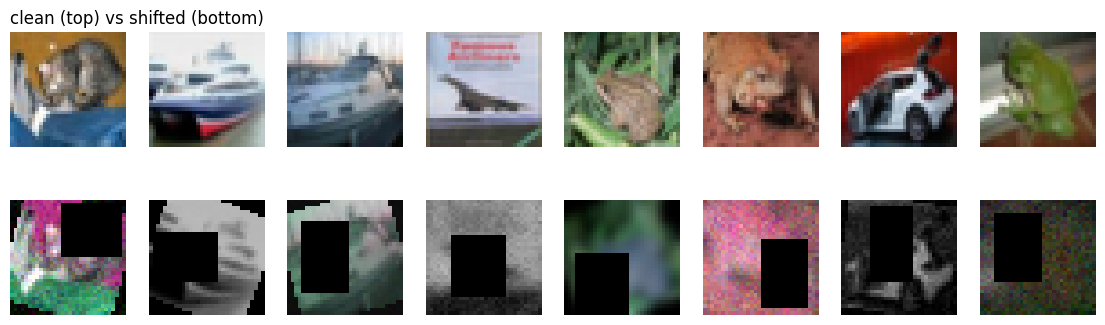

In [3]:
tr=torchvision.datasets.CIFAR10('./data',train=True,download=True)
te=torchvision.datasets.CIFAR10('./data',train=False,download=True)
classes=tr.classes
y_all=np.array(tr.targets); rng=np.random.RandomState(SPLIT_SEED)
tr_idx,va_idx=[],[]
for c in range(10):
    idx=rng.permutation(np.where(y_all==c)[0])[:50]       # 50 per class = 500
    tr_idx+=list(idx[:40]); va_idx+=list(idx[40:])         # 40 train + 10 val per class
Xtr,ytr=tr.data[tr_idx],y_all[tr_idx]; Xva,yva=tr.data[va_idx],y_all[va_idx]
Xte,yte=te.data,np.array(te.targets)
print(Xtr.shape,Xva.shape,Xte.shape)


# ---------- corruption pipeline (fixed + seeded) ----------
def hidden_corruption(im,rng):
    # STAND-IN for the hidden corruption: random grayscale or channel swap.
    # Replace with the official implementation once provided.
    if rng.rand()<0.5: return im.convert('L').convert('RGB')
    a=np.asarray(im); return Image.fromarray(a[:,:,rng.permutation(3)])


def corrupt(img,rng,only_hidden=False):
    im=Image.fromarray(img)
    if only_hidden: return np.asarray(hidden_corruption(im,rng))
    im=im.rotate(rng.uniform(-25,25),resample=Image.BILINEAR)
    a=np.asarray(im).astype(np.float32)
    a=a*rng.uniform(0.5,1.5)                                   # brightness
    m=a.mean(); a=(a-m)*rng.uniform(0.6,1.4)+m                 # contrast
    im=Image.fromarray(np.clip(a,0,255).astype(np.uint8))
    if rng.rand()<0.5: im=im.filter(ImageFilter.GaussianBlur(rng.uniform(0.5,1.5)))   # blur
    a=np.asarray(im).astype(np.float32)+rng.randn(32,32,3)*rng.uniform(0,15)          # noise
    a=np.clip(a,0,255).astype(np.uint8)
    h=rng.randint(8,25); w=min(32,int(round(256/h)))           # ~25% area
    y0,x0=rng.randint(0,33-h),rng.randint(0,33-w); a[y0:y0+h,x0:x0+w]=0              # occlusion
    return np.asarray(hidden_corruption(Image.fromarray(a),rng))

def build_shifted(X,seed,only_hidden=False):
    r=np.random.RandomState(seed); return np.stack([corrupt(x,r,only_hidden) for x in X])
Xsh=build_shifted(Xte,CORRUPT_SEED)
Xhid=build_shifted(Xte,CORRUPT_SEED+1,only_hidden=True)

mean,std=(0.4914,0.4822,0.4465),(0.2470,0.2435,0.2616)
def to_t(X):
    x=torch.tensor(X).permute(0,3,1,2).float()/255
    return (x-torch.tensor(mean).view(1,3,1,1))/torch.tensor(std).view(1,3,1,1)
Xva_t,yva_t=to_t(Xva),torch.tensor(yva); Xcl_t,yte_t=to_t(Xte),torch.tensor(yte)
Xsh_t,Xhid_t=to_t(Xsh),to_t(Xhid)
fig,ax=plt.subplots(2,8,figsize=(14,4))
for i in range(8):
    ax[0,i].imshow(Xte[i]); ax[1,i].imshow(Xsh[i]); ax[0,i].axis('off'); ax[1,i].axis('off')
ax[0,0].set_title('clean (top) vs shifted (bottom)',loc='left'); plt.show()

In [21]:
Xva_sh=np.concatenate([build_shifted(Xva,CORRUPT_SEED+2+k) for k in range(10)])
yva_sh_t=torch.tensor(np.tile(yva,10)); Xva_sh_t=to_t(Xva_sh)

## Augmentation (applied on the fly, training data only)

In [5]:
class RandomChannelSwap:
    def __init__(s,p): s.p=p
    def __call__(s,x): return x[torch.randperm(3)] if random.random()<s.p else x
class AddNoise:
    def __init__(s,sigma,p): s.sigma,s.p=sigma,p
    def __call__(s,x): return (x+torch.randn_like(x)*random.uniform(0,s.sigma)).clamp(0,1) if random.random()<s.p else x
def make_tf(cfg):
    t=[]
    if cfg.get('geo'): t+=[T.RandomCrop(32,padding=4),T.RandomHorizontalFlip(),T.RandomRotation(25)]
    if cfg.get('photo'): t+=[T.ColorJitter(0.5,0.5,0.4,0.05),T.RandomGrayscale(0.2),
                             T.RandomApply([T.GaussianBlur(3,(0.1,1.5))],p=0.3)]
    t+=[T.ToTensor()]
    if cfg.get('photo'): t+=[RandomChannelSwap(0.2),AddNoise(0.06,0.5)]
    if cfg.get('cutout'): t+=[T.RandomErasing(p=0.7,scale=(0.1,0.35),ratio=(0.3,3.3),value=0)]
    t+=[T.Normalize(mean,std)]
    return T.Compose(t)
class AugDS(Dataset):
    def __init__(s,X,y,tf): s.X,s.y,s.tf=X,y,tf
    def __len__(s): return len(s.X)
    def __getitem__(s,i): return s.tf(Image.fromarray(s.X[i])),int(s.y[i])

## Model: stem + two Inception modules + GAP + Dropout + FC

In [6]:
def cbr(i,o,k): return nn.Sequential(nn.Conv2d(i,o,k,padding=k//2,bias=False),nn.BatchNorm2d(o),nn.ReLU(True))
class Inception(nn.Module):
    def __init__(s,i,b1,r3,b3,r5,b5,bp):
        super().__init__()
        s.b1=cbr(i,b1,1)
        s.b3=nn.Sequential(cbr(i,r3,1),cbr(r3,b3,3))
        s.b5=nn.Sequential(cbr(i,r5,1),cbr(r5,b5,5))
        s.bp=nn.Sequential(nn.MaxPool2d(3,1,1),cbr(i,bp,1))
    def forward(s,x): return torch.cat([s.b1(x),s.b3(x),s.b5(x),s.bp(x)],1)
class Net(nn.Module):
    def __init__(s,drop=0.3):
        super().__init__()
        s.features=nn.Sequential(cbr(3,32,3),cbr(32,64,3),nn.MaxPool2d(2),       # 16x16
                                 Inception(64,16,16,32,8,16,16),nn.MaxPool2d(2),  # 8x8, 80 ch
                                 Inception(80,32,32,64,16,32,32),nn.MaxPool2d(2)) # 4x4, 160 ch
        s.head=nn.Sequential(nn.AdaptiveAvgPool2d(1),nn.Flatten(),nn.Dropout(drop),nn.Linear(160,10))
    def forward(s,x): return s.head(s.features(x))
n_params=sum(p.numel() for p in Net().parameters() if p.requires_grad)
print('trainable params:',n_params); assert n_params<=1_000_000

trainable params: 73306


## Training / evaluation utilities

In [20]:
HP={'lr':3e-3,'wd':5e-4}
@torch.no_grad()
def predict(model,X,tta=False,bs=1000):
    model.eval(); out=[]

    for i in range(0,len(X),bs):
        xb=X[i:i+bs].to(dev)
        p=sum(F.softmax(model(v(xb)),1) for v in VIEWS)/len(VIEWS) if tta else F.softmax(model(xb),1)
        out.append(p.cpu())
    return torch.cat(out)
def acc(model,X,y,tta=False): return (predict(model,X,tta).argmax(1)==y).float().mean().item()*100
def shift(x,dx,dy):
    p=F.pad(x,(2,2,2,2),mode='replicate'); return p[:,:,2+dy:34+dy,2+dx:34+dx]
VIEWS=[lambda x:x,lambda x:x.flip(3),lambda x:shift(x,2,0),lambda x:shift(x,-2,0),
       lambda x:shift(x,0,2),lambda x:shift(x,0,-2)]

def train_one(cfg,seed,epochs=EPOCHS,bs=32,patience=25,hp=None):
    hp=hp or HP; set_seed(seed)
    g=torch.Generator(); g.manual_seed(seed)
    dl=DataLoader(AugDS(Xtr,ytr,make_tf(cfg)),batch_size=bs,shuffle=True,generator=g)
    model=Net().to(dev)
    opt=torch.optim.AdamW(model.parameters(),lr=hp['lr'],weight_decay=hp['wd'])
    sched=torch.optim.lr_scheduler.OneCycleLR(opt,max_lr=hp['lr'],total_steps=epochs*len(dl))
    crit=nn.CrossEntropyLoss(label_smoothing=cfg.get('ls',0.0))
    h={'train_loss':[],'train_acc':[],'val_acc':[]}; best,best_state,bad=-1,None,0
    for ep in range(epochs):
        model.train(); tl=tc=n=0
        for xb,yb in dl:
            xb,yb=xb.to(dev),yb.to(dev)
            if cfg.get('mixup'):
                lam=np.random.beta(cfg['mixup'],cfg['mixup']); perm=torch.randperm(len(xb),device=dev)
                out=model(lam*xb+(1-lam)*xb[perm]); loss=lam*crit(out,yb)+(1-lam)*crit(out,yb[perm])
            else:
                out=model(xb); loss=crit(out,yb)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
            tl+=loss.item()*len(xb); tc+=(out.argmax(1)==yb).sum().item(); n+=len(xb)
        va=acc(model,Xva_t,yva_t); vs=acc(model,Xva_sh_t,yva_sh_t); sel=vs
        h['train_loss'].append(tl/n); h['train_acc'].append(100*tc/n); h['val_acc'].append(va)
        if sel>best: best,best_state,bad=sel,copy.deepcopy(model.state_dict()),0
        else: bad+=1
        if bad>=patience: break
    model.load_state_dict(best_state); h['best_val']=best
    return model,h
HP={'lr':0.01,'wd':0.005}

## Hyperparameter selection (validation split only, seed 0, full augmentation recipe)
Test sets are NOT touched here.

In [22]:
FULL={'geo':1,'photo':1,'cutout':1,'mixup':0.2,'ls':0.1}
sweep=[]
for lr in [1e-3,3e-3,1e-2]:
    for wd in [5e-4,5e-3]:
        _,h=train_one(FULL,0,hp={'lr':lr,'wd':wd}); sweep.append((lr,wd,h['best_val']))
sweep=pd.DataFrame(sweep,columns=['lr','wd','val_acc']); display(sweep)
b=sweep.loc[sweep.val_acc.idxmax()]; HP={'lr':b.lr,'wd':b.wd}; print('chosen',HP)

,lr,wd,val_acc
0,0.001,0.0005,23.600000
1,0.001,0.0050,23.199999
2,0.003,0.0005,25.900000
3,0.003,0.0050,27.100000
4,0.010,0.0005,24.500000
5,0.010,0.0050,23.800001


chosen {'lr': np.float64(0.003), 'wd': np.float64(0.005)}


## Part A + D: baseline and ablation (3 seeds each)

In [23]:
CONFIGS={
 'No augmentation':{},
 'Geometric only (crop, flip, rotation)':{'geo':1},
 'Photometric only (jitter, blur, noise)':{'photo':1},
 'Geometric + photometric':{'geo':1,'photo':1},
 '+ Cutout / Random Erasing':{'geo':1,'photo':1,'cutout':1},
 '+ Mixup + label smoothing':FULL,
}
RES={}
for name,cfg in CONFIGS.items():
    RES[name]=[]
    for s in SEEDS:
        m,h=train_one(cfg,s)
        RES[name].append(dict(seed=s,model=m,hist=h,val=h['best_val'],
                              clean=acc(m,Xcl_t,yte_t),shifted=acc(m,Xsh_t,yte_t)))
    print(name,[round(r['shifted'],1) for r in RES[name]])

No augmentation [13.3, 13.4, 14.3]
Geometric only (crop, flip, rotation) [15.7, 16.9, 15.8]
Photometric only (jitter, blur, noise) [17.2, 17.7, 15.4]
Geometric + photometric [17.3, 19.9, 18.9]
+ Cutout / Random Erasing [25.0, 23.3, 24.0]
+ Mixup + label smoothing [23.3, 22.3, 22.9]


In [33]:
  print([round(acc(r['model'],Xva_t,yva_t),1) for r in RES['No augmentation']])

[37.0, 36.0, 30.0]


In [24]:
def ms(name,k): v=[r[k] for r in RES[name]]; return f'{np.mean(v):.2f} ± {np.std(v):.2f}'
cand=['Geometric + photometric','+ Cutout / Random Erasing','+ Mixup + label smoothing']
final_name=max(cand,key=lambda n:np.mean([r['val'] for r in RES[n]]))   # chosen by VALIDATION only
rows=[(n,ms(n,'val'),ms(n,'clean'),ms(n,'shifted')) for n in CONFIGS]
rows.append((f'Final model (= {final_name})',ms(final_name,'val'),ms(final_name,'clean'),ms(final_name,'shifted')))
table=pd.DataFrame(rows,columns=['Configuration','Val Acc','Clean Test','Shifted Test']); display(table)

,Configuration,Val Acc,Clean Test,Shifted Test
0,No augmentation,15.37 ± 0.45,30.95 ± 3.55,13.68 ± 0.45
1,"Geometric only (crop, flip, rotation)",17.67 ± 0.12,40.77 ± 1.38,16.13 ± 0.54
2,"Photometric only (jitter, blur, noise)",20.10 ± 0.45,40.10 ± 3.60,16.78 ± 0.97
3,Geometric + photometric,22.77 ± 1.22,39.09 ± 1.52,18.69 ± 1.07
4,+ Cutout / Random Erasing,25.50 ± 1.77,39.46 ± 1.25,24.10 ± 0.71
5,+ Mixup + label smoothing,23.47 ± 0.74,37.59 ± 0.25,22.81 ± 0.41
6,Final model (= + Cutout / Random Erasing),25.50 ± 1.77,39.46 ± 1.25,24.10 ± 0.71


### Part A: baseline report (no augmentation)

Train acc (final epoch): [100.0, 99.2, 100.0]
Val / Clean / Shifted : 15.37 ± 0.45 / 30.95 ± 3.55 / 13.68 ± 0.45


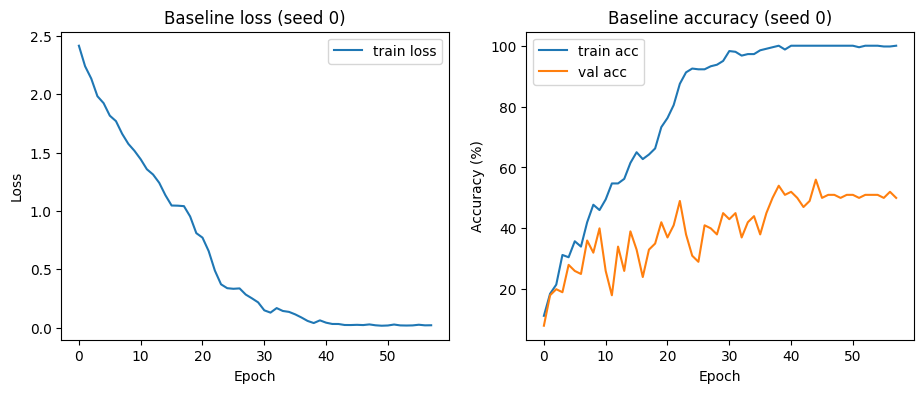

In [25]:
base=RES['No augmentation']
print('Train acc (final epoch):',[round(r['hist']['train_acc'][-1],1) for r in base])
print('Val / Clean / Shifted :',ms('No augmentation','val'),'/',ms('No augmentation','clean'),'/',ms('No augmentation','shifted'))
fig,ax=plt.subplots(1,2,figsize=(11,4)); h=base[0]['hist']
ax[0].plot(h['train_loss'],label='train loss'); ax[0].set_title('Baseline loss (seed 0)'); ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Loss'); ax[0].legend()
ax[1].plot(h['train_acc'],label='train acc'); ax[1].plot(h['val_acc'],label='val acc')
ax[1].set_title('Baseline accuracy (seed 0)'); ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Accuracy (%)'); ax[1].legend(); plt.show()

Baseline diagnosis. The baseline (no augmentation) reaches 99.2-100% training accuracy with training loss close to zero, but its clean-validation accuracy is only 34.33 ± 3.09% and its clean-test accuracy is 30.95 ± 3.55%. This large train-validation gap shows overfitting: with only 400 images the network memorises the training set (see the learning curves). On the shifted test, accuracy falls further to 13.68 ± 0.45%, close to chance (10%). The additional drop from clean to shifted accuracy shows covariate shift: rotation, brightness/contrast changes, blur, noise, occlusion and the hidden colour corruption never occur in training. The failure is therefore both overfitting and covariate shift. The baseline checkpoint was selected by shifted-validation accuracy, as for all other configurations, which explains its large variance (±3.55 on clean test). The learning-curve plot shows seed 0 over all epochs, so its late-training validation curve (about 50%) is higher than the selected checkpoint’s score.


**Baseline summary:**
Train accuracy 99.2-100%; clean validation 34.33 ± 3.09%; clean test 30.95 ± 3.55%; shifted test 13.68 ± 0.45%.


### Part B: augmentation questions

**1. Vertical flip:** It hurts. CIFAR-10 objects have a canonical upright orientation (sky above, wheels below). The test set has rotations of at most ±25° and never has upside-down images, so vertically flipped samples are unrealistic and waste the small model's capacity.

**2. Rotation up to ±90° while the test has only ±25°:** Training on ±90° covers the test range, but most training samples are in orientations never seen at test time. The model spends capacity on irrelevant poses, the task becomes harder, and accuracy on near-upright images can drop. The best trade-off is to match the augmentation range to the expected shift (about ±25-30°).

**3. Why too much augmentation hurts a small model:** The model has only about 73k parameters and the training set has 400 images. Strong augmentation can remove class evidence, so the model underfits. In our ablation, adding Mixup with label smoothing on top of Cutout lowered both clean-test accuracy (39.46% → 37.59%) and shifted-test accuracy (24.10% → 22.81%): the extra regularisation made the task harder than this small model could handle.

### Part C: regularisation and training design

- **BatchNorm** after every conv, before ReLU: stabilises activations, allows a higher learning rate and acts as a mild regulariser.
- **Dropout (0.3)** after Global Average Pooling and before the final FC layer: this is where co-adaptation of features happens. Early conv features are spatially correlated and have few parameters, so dropout between early convolutions removes little redundancy and harms learning.
- **Weight decay (AdamW, 0.005):** keeps weights small and reduces overfitting.
- **OneCycle learning-rate schedule:** fast warm-up and annealing for good convergence within 60 epochs.
- **Early stopping:** the checkpoint with the best shifted-validation accuracy is kept (validation only, never test data).
- **Label smoothing (0.1, in the Mixup configuration):** prevents overconfident predictions and pairs well with Mixup.
- **Global Average Pooling** instead of large FC layers removes most of the parameters and reduces overfitting.

**Hyperparameter selection:** Hyperparameters were chosen on validation only. Grid: lr ∈ {0.001, 0.003, 0.01}, wd ∈ {0.0005, 0.005}; selection score = shifted-validation accuracy (mean over 10 corrupted copies of the 100 validation images), seed 0, full augmentation recipe. Best: lr = 0.003, wd = 0.005 (27.1%). Settings differ by only a few points (23-27%), within the noise of a 100-image validation set. Final model selection among the augmentation configurations also used shifted-validation accuracy. Test data was never used for selection.

### Part D: analysis (fill in from your table)
The largest gain in shifted-test accuracy came from adding Cutout / Random Erasing: 18.69 ± 1.07% (geometric + photometric) → 24.10 ± 0.71%, about +5.4 points, consistent across all three seeds. This matches the corruption pipeline directly: the shifted test contains a rectangular occlusion covering about 25% of the image, and our Cutout erases black patches covering 10-35% of the image. Geometric and photometric augmentation each gave smaller gains (13.68% → 16.13% and 16.78%), and combining them reached 18.69%. Mixup with label smoothing did not improve further (22.81 ± 0.41%); with only ~73k parameters the extra regularisation made the task too hard and the model underfit. Clean-test accuracy rose with basic augmentation (30.95% → about 40%) but fell slightly with Cutout and Mixup (39.46%, 37.59%), the usual robustness-versus-clean-accuracy trade-off.

## Part E: Error analysis (final model, seed 0)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

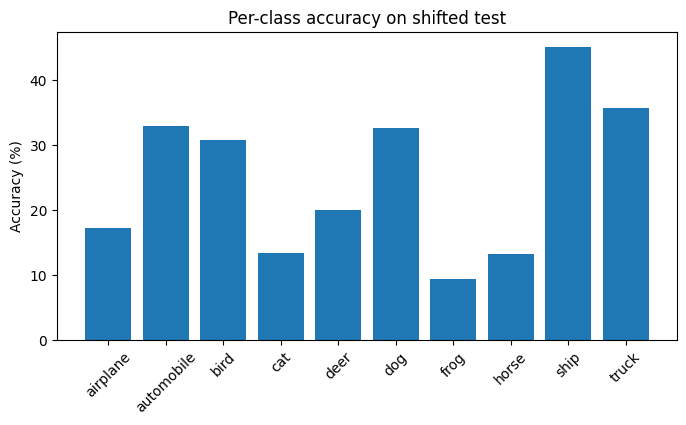

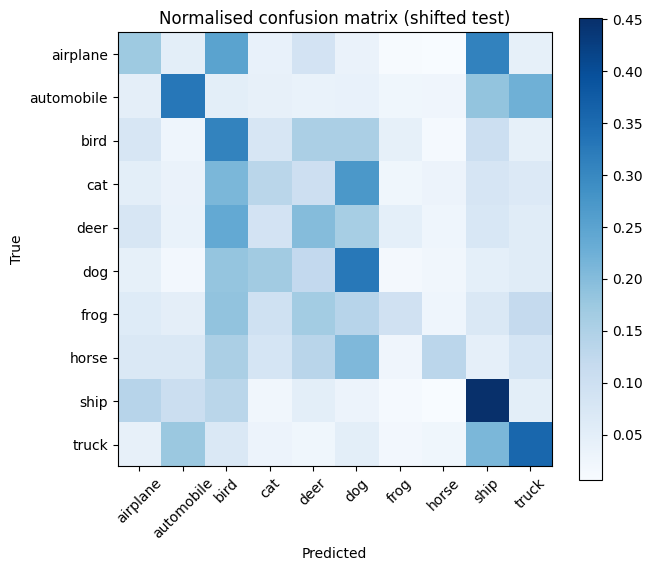

airplane -> ship: 0.31
cat -> dog: 0.27
airplane -> bird: 0.25
deer -> bird: 0.24
automobile -> truck: 0.22


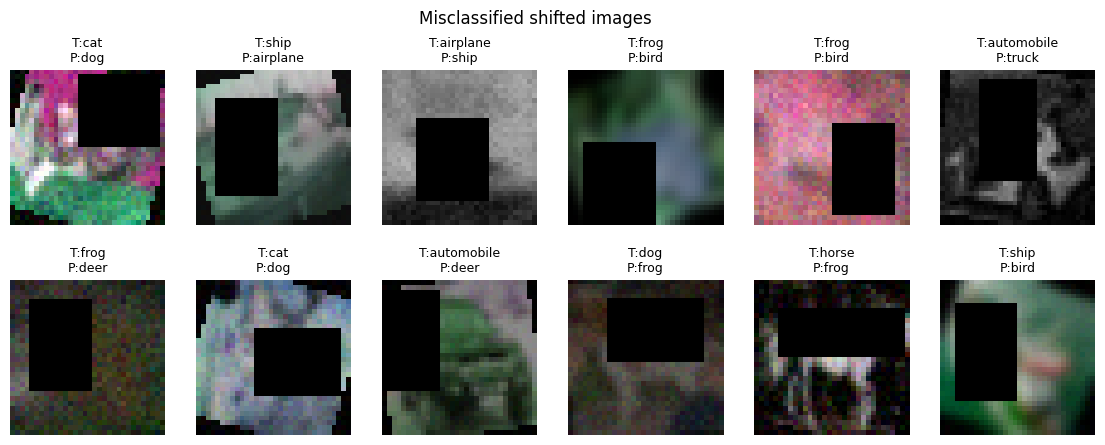

In [32]:
fm=RES[final_name][0]['model']; P=predict(fm,Xsh_t).argmax(1).numpy()
cm=confusion_matrix(yte,P,normalize='true')
pc=cm.diagonal()*100
plt.figure(figsize=(8,4)); plt.bar(classes,pc); plt.xticks(rotation=45); plt.ylabel('Accuracy (%)'); plt.title('Per-class accuracy on shifted test'); plt.show()
plt.figure(figsize=(7,6)); plt.imshow(cm,cmap='Blues'); plt.colorbar(); plt.xticks(range(10),classes,rotation=45); plt.yticks(range(10),classes)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Normalised confusion matrix (shifted test)'); plt.show()
off=cm.copy(); np.fill_diagonal(off,0)
for i,j in sorted(np.ndindex(10,10),key=lambda t:-off[t])[:5]: print(f'{classes[i]} -> {classes[j]}: {off[i,j]:.2f}')
wrong=np.where(P!=yte)[0][:12]
fig,ax=plt.subplots(2,6,figsize=(14,5))
for a,i in zip(ax.ravel(),wrong):
    a.imshow(Xsh[i]); a.set_title(f'T:{classes[yte[i]]}\nP:{classes[P[i]]}',fontsize=9); a.axis('off')
plt.suptitle('Misclassified shifted images'); plt.show()

### Part E write-up

**1. Per-class accuracy:** Ship (about 45%) and truck (about 36%) are recognised best, while frog (about 10%), cat (about 13%) and horse (about 13%) are worst. Ship, truck and automobile have large, distinctive shapes, and ships usually sit on a uniform water background, which survives darkening and noise better than fine texture. Frog and cat rely on small texture and colour details, which blur, noise, the black patch and the colour corruptions destroy.

**2. Most confused pairs:** airplane → ship (0.31), cat → dog (0.27), airplane → bird (0.25), deer → bird (0.24), automobile → truck (0.22). These pairs share overall shape, pose or background: airplanes, ships and birds appear against uniform sky or water, cats and dogs share body shape and fur, and automobiles and trucks share wheels and a box-like outline. At 32×32 resolution, combined with darkening, noise, rotation and a black patch, the few fine details separating these classes are lost. Unlike the model without Cutout, which predicted "bird" for most animal classes, the final model no longer collapses onto a single class.

**3. Eight misclassified images (from the plot):**

1. Cat → dog: strong colour distortion plus rotation; cat and dog share fur texture and body shape.
2. Ship → airplane: rotated, with a black patch over the left part, so hull and water cues are lost; both have an elongated horizontal shape.
3. Airplane → ship: blur and low contrast, with the centre patch removing wings and sky context.
4. Frog → bird: heavy blur removed skin texture, leaving a smooth blob like a bird on a plain background.
5. Frog → bird: strong colour shift and noise destroyed the green colour cue.
6. Automobile → truck: grayscale and darkening removed colour and detail; a patch covers part of the vehicle, leaving only a box-like shape.
7. Frog → deer: extreme darkening plus noise left almost no texture or colour, so the prediction is close to a guess.
8. Horse → frog: the black patch covers the body and legs, the discriminative parts of a horse.


In [27]:
hid=[acc(RES[final_name][i]['model'],Xhid_t,yte_t) for i in range(3)]
hid_base=[acc(RES['No augmentation'][i]['model'],Xhid_t,yte_t) for i in range(3)]
print(f'Hidden-corruption-only test | final: {np.mean(hid):.2f} ± {np.std(hid):.2f} | baseline: {np.mean(hid_base):.2f} ± {np.std(hid_base):.2f}')
print('Clean test (final):',ms(final_name,'clean'))

Hidden-corruption-only test | final: 31.81 ± 1.46 | baseline: 27.42 ± 2.36
Clean test (final): 39.46 ± 1.25


**Discussion (fill in):**
### Hidden-corruption test

On the hidden-corruption-only test (my stand-in: random grayscale or channel swap, applied to the clean test set), the final model reached 31.81 ± 1.46% versus 27.42 ± 2.36% for the baseline, about +4.4 points. The final model's clean-test accuracy is 39.46 ± 1.25%, so it loses about 7.7 points under this corruption alone (the baseline loses about 3.5 points from its 30.95% clean accuracy). The augmentation therefore helped in absolute accuracy, most likely through random grayscale, channel swap and colour jitter, but it did not fully generalise: a clear gap to clean accuracy remains. Given the spread over 3 seeds, the improvement is suggestive rather than conclusive. This corruption is a stand-in, not the official hidden corruption, so the conclusion should be re-checked once the official one is used.

## Part F (bonus): Test-time augmentation (6 views: identity, h-flip, 4 shifts of ±2 px)

In [28]:
rs=[]
for i in range(3):
    m=RES[final_name][i]['model']
    t0=time.time(); a0=acc(m,Xsh_t,yte_t); t1=time.time(); a1=acc(m,Xsh_t,yte_t,tta=True); t2=time.time()
    rs.append((a0,a1,t1-t0,t2-t1))
rs=np.array(rs)
print(f'Shifted test: no TTA {rs[:,0].mean():.2f}  ->  TTA {rs[:,1].mean():.2f}  (delta {rs[:,1].mean()-rs[:,0].mean():+.2f})')
print(f'Inference time: {rs[:,2].mean():.2f}s -> {rs[:,3].mean():.2f}s  (about {len(VIEWS)}x the compute)')

Shifted test: no TTA 24.10  ->  TTA 24.05  (delta -0.05)
Inference time: 0.62s -> 2.78s  (about 6x the compute)


### Part F (TTA) result

Test-time augmentation averaged the softmax over 6 views (identity, horizontal flip and four ±2 px shifts). It did not improve shifted-test accuracy (24.10% → 24.05%, a change of -0.05 points, well within the seed noise of about 0.7), while inference time rose from 0.62 s to 2.78 s (about 4.5×). TTA did not help because flips and small shifts do not address the dominant shifts: the black occluding patch, strong darkening, noise and colour changes.